# 04. Bank Account Fraud – Dataset Profiling

## Objectives

- Verify schema and binary labels across six variants.
- Examine monthly sample volume and fraud prevalence.
- Identify missing and sentinel values.
- Explore monthly feature drift on the Base variant.
- Assess suitability for secondary experiments.

BAF is analyzed at monthly resolution.
No artificial daily timestamps are generated.

## 1. Import và cấu hình

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_config, load_manifest, load_baf

from src.data_profiling import (
    dataset_overview,
    column_profile,
    target_validation,
    export_report,
)

from src.temporal_analysis import temporal_summary
from src.drift_metrics import feature_drift_report

config = load_config()
baf_config = config["datasets"]["baf"]

manifest = load_manifest()

REPORT_DIR = PROJECT_ROOT / "reports/data_profiling/baf"

FIGURE_DIR = PROJECT_ROOT / "reports/figures/baf"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TARGET = baf_config["target_column"]
TIME = baf_config["time_column"]

variants = baf_config["variants"]

## 2. Profiling cả 6 biến thể

In [2]:
overview_records = []
monthly_records = []
missing_records = []
sentinel_records = []

reference_schema = None

for variant in tqdm(variants):

    df = load_baf(variant)

    variant_name = Path(variant).stem

    record = manifest.loc[manifest["file_name"].eq(variant)]

    assert len(record) == 1

    record = record.iloc[0]

    assert df.shape == (int(record["num_rows"]), int(record["num_columns"]))

    if reference_schema is None:
        reference_schema = set(df.columns)

    schema_match = set(df.columns) == reference_schema

    target_report = target_validation(df, TARGET).iloc[0].to_dict()

    assert target_report["missing_labels"] == 0
    assert target_report["invalid_labels"] == 0

    assert df[TIME].notna().all()
    assert set(df[TIME].unique()) == set(range(8))

    overview_records.append(
        {
            "variant": variant_name,
            "num_rows": len(df),
            "num_columns": df.shape[1],
            "schema_match": schema_match,
            "fraud_count": target_report["fraud_count"],
            "fraud_rate_pct": target_report["fraud_rate_pct"],
            "num_months": df[TIME].nunique(),
            "total_missing": int(df.isna().sum().sum()),
        }
    )

    monthly = temporal_summary(df, group_column=TIME, target_column=TARGET)

    monthly["variant"] = variant_name

    monthly_records.append(monthly)

    missing = df.isna().mean().rename("missing_rate").reset_index()

    missing.columns = ["column_name", "missing_rate"]

    missing["variant"] = variant_name

    missing_records.append(missing)

    numeric_df = df.select_dtypes(include="number").drop(
        columns=[TARGET, TIME], errors="ignore"
    )

    sentinel = numeric_df.eq(-1).mean().rename("minus_one_rate").reset_index()

    sentinel.columns = ["column_name", "minus_one_rate"]

    sentinel["variant"] = variant_name

    sentinel_records.append(sentinel)

    if variant == "Base.csv":

        base_profile = column_profile(df)

        base_profile["role"] = np.select(
            [
                base_profile["column_name"].eq(TARGET),
                base_profile["column_name"].eq(TIME),
            ],
            ["target", "temporal_metadata"],
            default="feature",
        )

        export_report(base_profile, REPORT_DIR / "base_data_dictionary.csv")

    del numeric_df
    del df

variant_summary = pd.DataFrame(overview_records)

monthly_stats = pd.concat(monthly_records, ignore_index=True)

missing_summary = pd.concat(missing_records, ignore_index=True)

sentinel_summary = pd.concat(sentinel_records, ignore_index=True)

display(variant_summary)

export_report(variant_summary, REPORT_DIR / "baf_variant_summary.csv")

export_report(monthly_stats, REPORT_DIR / "baf_monthly_statistics.csv")

export_report(missing_summary, REPORT_DIR / "baf_missing_summary.csv")

export_report(sentinel_summary, REPORT_DIR / "baf_sentinel_summary.csv")

  0%|          | 0/6 [00:00<?, ?it/s]

Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\base_data_dictionary.csv


,variant,num_rows,num_columns,schema_match,fraud_count,fraud_rate_pct,num_months,total_missing
0,Base,1000000,32,True,11029,1.1029,8,0
1,Variant I,1000000,32,True,11029,1.1029,8,0
2,Variant II,1000000,32,True,11029,1.1029,8,0
3,Variant III,1000000,34,False,11030,1.1030,8,0
4,Variant IV,1000000,32,True,11030,1.1030,8,0
5,Variant V,1000000,34,False,11030,1.1030,8,0


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\baf_variant_summary.csv
Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\baf_monthly_statistics.csv
Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\baf_missing_summary.csv
Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\baf_sentinel_summary.csv


## 3. Kiểm tra Missing và Sentinel Values

In [3]:
base_sentinel = sentinel_summary.loc[
    sentinel_summary["variant"].eq("Base") & sentinel_summary["minus_one_rate"].gt(0)
].sort_values("minus_one_rate", ascending=False)

display(base_sentinel)

print("All variants have matching column names:", variant_summary["schema_match"].all())

display(
    monthly_stats.groupby("variant").agg(
        min_monthly_fraud=("num_fraud", "min"), max_monthly_fraud=("num_fraud", "max")
    )
)

,column_name,minus_one_rate,variant
2,prev_address_months_count,0.712920,Base
17,bank_months_count,0.253635,Base
3,current_address_months_count,0.004254,Base
21,session_length_in_minutes,0.002015,Base
13,credit_risk_score,0.000488,Base
23,device_distinct_emails_8w,0.000359,Base


All variants have matching column names: False


,min_monthly_fraud,max_monthly_fraud
variant,,
Base,1198,1500
Variant I,1198,1500
Variant II,1198,1500
Variant III,936,2136
Variant IV,936,2135
Variant V,936,2136


## 4. Fraud Rate và Sample Volume theo tháng

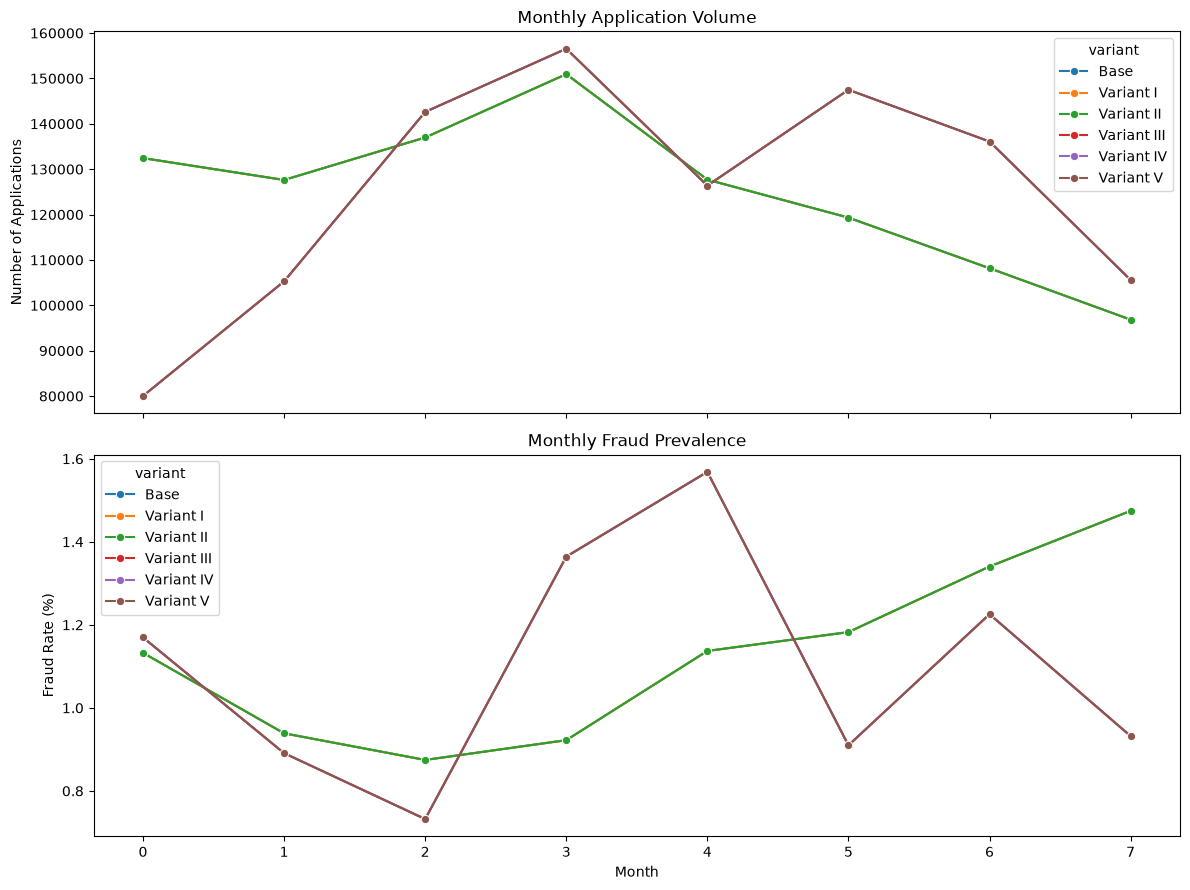

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

sns.lineplot(
    data=monthly_stats,
    x=TIME,
    y="num_transactions",
    hue="variant",
    marker="o",
    ax=axes[0],
)

axes[0].set_title("Monthly Application Volume")
axes[0].set_ylabel("Number of Applications")

sns.lineplot(
    data=monthly_stats,
    x=TIME,
    y="fraud_rate_pct",
    hue="variant",
    marker="o",
    ax=axes[1],
)

axes[1].set_title("Monthly Fraud Prevalence")
axes[1].set_ylabel("Fraud Rate (%)")
axes[1].set_xlabel("Month")
axes[1].set_xticks(range(8))

plt.tight_layout()

plt.savefig(FIGURE_DIR / "baf_monthly_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

## 5. Monthly Drift trên Base

In [5]:
base_df = load_baf("Base.csv")

features = [col for col in base_df.columns if col not in [TARGET, TIME]]

categorical_features = (
    base_df[features].select_dtypes(exclude="number").columns.tolist()
)

reference_df = base_df.loc[base_df[TIME].eq(0), features]

monthly_drift_records = []

for month in tqdm(range(1, 8)):

    current_df = base_df.loc[base_df[TIME].eq(month), features]

    report = feature_drift_report(
        reference_df=reference_df,
        current_df=current_df,
        features=features,
        categorical_features=categorical_features,
        config=config["drift_eda"],
        random_seed=config["project"]["random_seed"],
    )

    report["month"] = month

    monthly_drift_records.append(report)

baf_drift = pd.concat(monthly_drift_records, ignore_index=True)

export_report(baf_drift, REPORT_DIR / "base_monthly_feature_drift.csv")

display(baf_drift.head())

  0%|          | 0/7 [00:00<?, ?it/s]

Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\base_monthly_feature_drift.csv


,feature,feature_type,psi,ks_statistic,reference_non_missing,current_non_missing,reference_missing_rate,current_missing_rate,missing_rate_change,missing_rate_drift,sufficient_samples,month
0,income,numerical,0.007930,0.0344,132440,127620,0.0,0.0,0.0,0.0,True,1
1,name_email_similarity,numerical,0.064549,0.0899,132440,127620,0.0,0.0,0.0,0.0,True,1
2,prev_address_months_count,numerical,0.012662,0.0582,132440,127620,0.0,0.0,0.0,0.0,True,1
3,current_address_months_count,numerical,0.051954,0.0896,132440,127620,0.0,0.0,0.0,0.0,True,1
4,customer_age,numerical,0.033617,0.0468,132440,127620,0.0,0.0,0.0,0.0,True,1


## 6. Tổng hợp Monthly Drift

,month,valid_psi_features,median_psi,p90_psi,median_ks,mean_missing_drift
0,1,30,0.034986,0.200327,0.0723,0.0
1,2,30,0.049901,0.241802,0.0714,0.0
2,3,30,0.023733,0.328248,0.0663,0.0
3,4,30,0.043831,0.409463,0.0736,0.0
4,5,30,0.054596,0.751626,0.0964,0.0
5,6,30,0.049484,0.997509,0.0976,0.0
6,7,30,0.067787,1.637112,0.0899,0.0


Saved: D:\UniversityCourses\HK7\IE212.R12\Project\fraud-retraining\reports\data_profiling\baf\base_monthly_drift_summary.csv


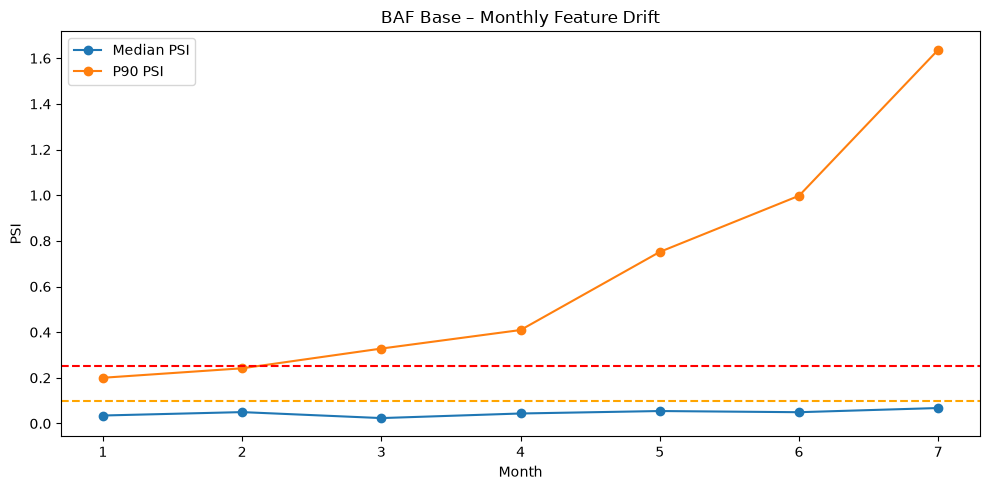

In [6]:
baf_drift_summary = (
    baf_drift.groupby("month")
    .agg(
        valid_psi_features=("psi", "count"),
        median_psi=("psi", "median"),
        p90_psi=("psi", lambda x: x.quantile(0.90)),
        median_ks=("ks_statistic", "median"),
        mean_missing_drift=("missing_rate_drift", "mean"),
    )
    .reset_index()
)

display(baf_drift_summary)

export_report(baf_drift_summary, REPORT_DIR / "base_monthly_drift_summary.csv")

plt.figure(figsize=(10, 5))

plt.plot(
    baf_drift_summary["month"],
    baf_drift_summary["median_psi"],
    marker="o",
    label="Median PSI",
)

plt.plot(
    baf_drift_summary["month"],
    baf_drift_summary["p90_psi"],
    marker="o",
    label="P90 PSI",
)

plt.axhline(0.1, linestyle="--", color="orange")

plt.axhline(0.25, linestyle="--", color="red")

plt.title("BAF Base – Monthly Feature Drift")
plt.xlabel("Month")
plt.ylabel("PSI")
plt.xticks(range(1, 8))
plt.legend()
plt.tight_layout()

plt.savefig(FIGURE_DIR / "base_monthly_drift.png", dpi=300, bbox_inches="tight")

plt.show()

## Conclusion

The six BAF variants are inspected independently.

The analysis covers schema integrity, label distribution,
monthly sample volume, missing values and potential
sentinel values.

Monthly feature drift is explored on the Base variant.

BAF is retained as a secondary dataset for monthly
robustness experiments. Weekly retraining and daily
label-delay settings cannot be directly reproduced
using its monthly temporal resolution.